In [ ]:
import torch
import torchaudio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchaudio:", torchaudio.__version__)
print("GPU Available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch: 2.14.1+cu130
Torchaudio: 2.11.0+cu130
GPU Available: True
Using device: cuda


In [ ]:
import os
import random
import time
import copy
import glob

from pathlib import Path
from collections import Counter

import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
!pip install -U datasets huggingface_hub

In [ ]:

from datasets import load_dataset

hindi = load_dataset(
    "google/fleurs",
    "hi_in"
)

print(hindi)

README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

parquet-data/hi_in/train-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 1.53GB            

parquet-data/hi_in/train-00000-of-00001.(…): downloading bytes:           |  0.00B            

parquet-data/hi_in/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  162MB            

parquet-data/hi_in/validation-00000-of-0(…): downloading bytes:           |  0.00B            

parquet-data/hi_in/test-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B /  306MB            

parquet-data/hi_in/test-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2120 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/239 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/418 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 2120
    })
    validation: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 239
    })
    test: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 418
    })
})


In [ ]:
english = load_dataset(
    "google/fleurs",
    "en_us"
)

print(english)

parquet-data/en_us/train-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 1.72GB            

parquet-data/en_us/train-00000-of-00001.(…): downloading bytes:           |  0.00B            

parquet-data/en_us/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  237MB            

parquet-data/en_us/validation-00000-of-0(…): downloading bytes:           |  0.00B            

parquet-data/en_us/test-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B /  402MB            

parquet-data/en_us/test-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2602 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/394 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/647 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 2602
    })
    validation: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 394
    })
    test: Dataset({
        features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
        num_rows: 647
    })
})


In [ ]:
print(hindi["train"][0])

{'id': 93, 'num_samples': 138240, 'path': '/root/.cache/huggingface/datasets/downloads/extracted/d84cd21d7e2a1e02acc33f0f542109eae3f14413bd96886bc87b1e60e3f08f64/10002503286825416621.wav', 'audio': <datasets.features._torchcodec.AudioDecoder object at 0x794a64aeda90>, 'transcription': 'राजनीतिज्ञों ने कहा कि उन्होंने निर्णायक मत को अनावश्यक रूप से निर्धारित करने के लिए अफ़गान संविधान में काफी अस्पष्टता पाई थी', 'raw_transcription': 'राजनीतिज्ञों ने कहा कि उन्होंने निर्णायक मत को अनावश्यक रूप से निर्धारित करने के लिए अफ़गान संविधान में काफी अस्पष्टता पाई थी.', 'gender': 1, 'lang_id': 32, 'language': 'Hindi', 'lang_group_id': 4}


In [ ]:
hindi.save_to_disk("/content/FLEURS_Hindi")
english.save_to_disk("/content/FLEURS_English")

Saving the dataset (0/4 shards):   0%|          | 0/2120 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/239 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/418 [00:00<?, ? examples/s]

Saving the dataset (0/4 shards):   0%|          | 0/2602 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/394 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/647 [00:00<?, ? examples/s]

In [ ]:
import torch
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from datasets import load_from_disk

# Define target word mappings for classification
target_words = ['STOP', 'UP', 'GO', 'OFF', 'ON']

class FleursKeywordDataset(Dataset):
    def __init__(self, dataset_path, split="train", target_sr=16000, n_mels=40, max_len=16000):
        # Load saved dataset from disk
        self.dataset = load_from_disk(dataset_path)[split]
        self.target_sr = target_sr
        self.max_len = max_len
        self.melspec_transform = T.MelSpectrogram(
            sample_rate=target_sr,
            n_fft=400,
            hop_length=160,
            n_mels=n_mels
        )

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        # Extract audio waveform and sample rate
        # If audio is already a dictionary, standard Hugging Face datasets return 'array'
        audio_data = item['audio']
        waveform = torch.tensor(audio_data['array'], dtype=torch.float32)
        sr = audio_data['sampling_rate']

        # Resample if needed
        if sr != self.target_sr:
            resampler = T.Resample(orig_freq=sr, new_freq=self.target_sr)
            waveform = resampler(waveform)

        # Standardize duration (pad or truncate)
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)

        if waveform.shape[-1] < self.max_len:
            pad_len = self.max_len - waveform.shape[-1]
            waveform = F.pad(waveform, (0, pad_len))
        else:
            waveform = waveform[:, :self.max_len]

        # Extract Mel Spectrogram (Output shape: [1, n_mels, time_steps])
        mel_spec = self.melspec_transform(waveform)
        # Convert to log scale
        mel_spec = torch.log(mel_spec + 1e-9)

        # Label mapping
        transcription = item['transcription'].upper()
        label = class_to_idx['UNKNOWN']  # Default to UNKNOWN
        for word in target_words:
            if word in transcription:
                label = class_to_idx[word]
                break

        return mel_spec, label

# Initialize the train dataset and DataLoader
train_dataset = FleursKeywordDataset("/content/FLEURS_Hindi", split="train")
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

In [ ]:
!git clone https://github.com/Qualcomm-AI-research/bcresnet.git

Cloning into 'bcresnet'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 13 (delta 1), reused 0 (delta 0), pack-reused 7 (from 1)
Receiving objects: 100% (13/13), 231.00 KiB | 1.32 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [ ]:
import sys

sys.path.append("/content/bcresnet")

from bcresnet import BCResNets

print("BC-ResNet imported successfully!")

BC-ResNet imported successfully!


In [ ]:
CLASS_NAMES = [
    "STOP",
    "UP",
    "GO",
    "OFF",
    "ON",
    "UNKNOWN"
]

NUM_CLASSES = len(CLASS_NAMES)

class_to_idx = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

print(class_to_idx)

{'STOP': 0, 'UP': 1, 'GO': 2, 'OFF': 3, 'ON': 4, 'UNKNOWN': 5}


In [ ]:
model = BCResNets(
    base_c=64,
    num_classes=NUM_CLASSES
)

model = model.to(device)

print(model)

BCResNets(
  (cnn_head): Sequential(
    (0): Conv2d(1, 128, kernel_size=(5, 5), stride=(2, 1), padding=(2, 2), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (BCBlocks): ModuleList(
    (0): ModuleList(
      (0): BCResBlock(
        (f2): Sequential(
          (0): ConvBNReLU(
            (block): Sequential(
              (0): Conv2d(128, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
              (2): ReLU(inplace=True)
            )
          )
          (1): ConvBNReLU(
            (block): Sequential(
              (0): Conv2d(64, 64, kernel_size=(3, 1), stride=(1, 1), padding=(1, 0), groups=64, bias=False)
              (1): SubSpectralNorm(
                (ssnorm): BatchNorm2d(320, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
         

In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 319526
Trainable parameters: 319526


In [ ]:
dummy_input = torch.randn(
    2, 1, 40, 101
).to(device)

model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 1, 40, 101])
Output shape: torch.Size([2, 6])


In [ ]:
features, labels = next(iter(train_loader))

# Add the channel dimension to match (Batch, Channel, Height, Width)
features = features.unsqueeze(1)

print("Feature shape:", features.shape)
print("Label shape:", labels.shape)
print("Labels:", labels[:10])

assert features.ndim == 4
assert features.shape[1] == 1
assert features.shape[2] == 40
assert labels.min() >= 0
assert labels.max() < NUM_CLASSES

Feature shape: torch.Size([8, 1, 40, 101])
Label shape: torch.Size([8])
Labels: tensor([5, 5, 5, 5, 5, 5, 5, 5])


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 30

In [ ]:
def train_model(model, train_loader, criterion, optimizer, device):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(features)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(train_loader)

    return avg_loss, accuracy

In [ ]:
def validate_model(model, valid_loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for features, labels in valid_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model(features)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(valid_loader)

    return avg_loss, accuracy

In [ ]:
best_accuracy = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    # Modify train_model on-the-fly or unpack batches with unsqueeze(1)
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for features, labels in train_loader:
        features = features.unsqueeze(1).to(device)  # Add missing channel dimension
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_acc = 100 * correct / total
    train_loss = total_loss / len(train_loader)

    # Run validation natively here with the unsqueeze(1) fix as well
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    # Simple check if valid_loader exists, otherwise fallback to train_loader for debugging
    val_loader = valid_loader if 'valid_loader' in globals() else train_loader

    with torch.no_grad():
        for features, labels in val_loader:
            features = features.unsqueeze(1).to(device)  # Add missing channel dimension
            labels = labels.to(device)

            outputs = model(features)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_acc = 100 * correct / total
    val_loss = val_loss / len(val_loader)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(
            model.state_dict(),
            "/content/bcresnet_best.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/30] Train Loss: 0.1001 Train Acc: 98.54% Val Loss: 0.0401 Val Acc: 99.53%
Epoch [2/30] Train Loss: 0.0370 Train Acc: 99.53% Val Loss: 0.0397 Val Acc: 99.53%
Epoch [3/30] Train Loss: 0.0361 Train Acc: 99.53% Val Loss: 0.0830 Val Acc: 99.53%
Epoch [4/30] Train Loss: 0.0352 Train Acc: 99.53% Val Loss: 0.0355 Val Acc: 99.53%
Epoch [5/30] Train Loss: 0.0355 Train Acc: 99.53% Val Loss: 0.0571 Val Acc: 99.53%
Epoch [6/30] Train Loss: 0.0390 Train Acc: 99.53% Val Loss: 0.0372 Val Acc: 99.53%
Epoch [7/30] Train Loss: 0.0377 Train Acc: 99.53% Val Loss: 0.0377 Val Acc: 99.53%
Epoch [8/30] Train Loss: 0.0383 Train Acc: 99.53% Val Loss: 0.0352 Val Acc: 99.53%
Epoch [9/30] Train Loss: 0.0374 Train Acc: 99.53% Val Loss: 0.0346 Val Acc: 99.53%
Epoch [10/30] Train Loss: 0.0363 Train Acc: 99.53% Val Loss: 0.0370 Val Acc: 99.53%
Epoch [11/30] Train Loss: 0.0374 Train Acc: 99.53% Val Loss: 0.0350 Val Acc: 99.53%
Epoch [12/30] Train Loss: 0.0364 Train Acc: 99.53% Val Loss: 0.0362 Val Acc: 99.53%
E

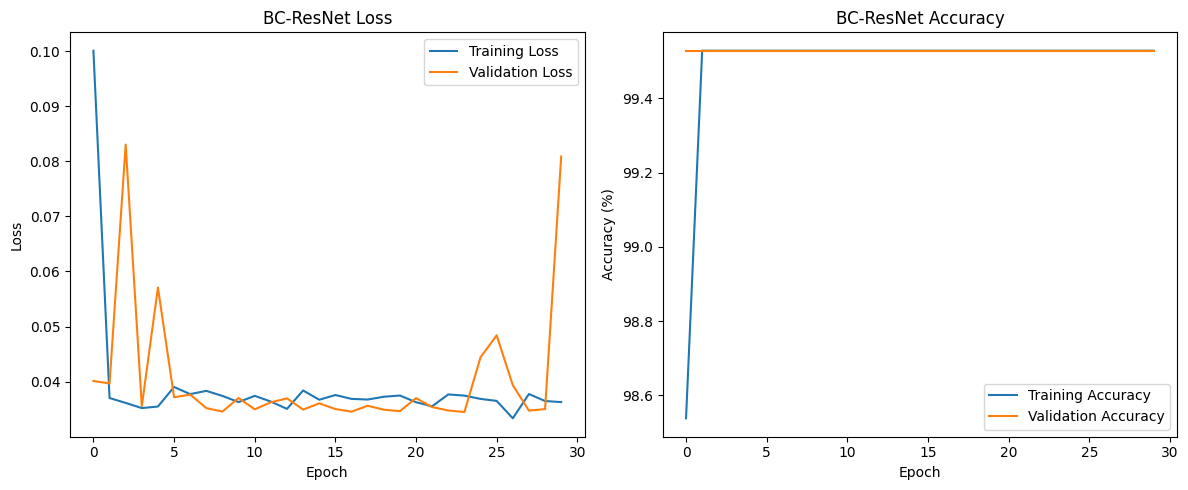

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.title("BC-ResNet Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history["train_accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")

plt.title("BC-ResNet Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/bcresnet_best.pth",
        map_location=device
    )
)

model.eval()

print("Best BC-ResNet model loaded!")

Best BC-ResNet model loaded!


In [ ]:
y_true = []
y_pred = []

# Initialize the test dataset and DataLoader
test_dataset = FleursKeywordDataset("/content/FLEURS_Hindi", split="test")
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

model.eval()

with torch.no_grad():
    # Note: Ensure test_loader is defined in your environment before running this cell
    for features, labels in test_loader:
        # Add the channel dimension to match (Batch, Channel, Height, Width) expected by BC-ResNet
        features = features.unsqueeze(1).to(device)

        outputs = model(features)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

Test Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

        STOP       0.00      0.00      0.00         0
          UP       0.00      0.00      0.00         0
          GO       0.00      0.00      0.00         0
         OFF       0.00      0.00      0.00         0
          ON       0.00      0.00      0.00         0
     UNKNOWN       1.00      1.00      1.00       418

    accuracy                           1.00       418
   macro avg       0.17      0.17      0.17       418
weighted avg       1.00      1.00      1.00       418



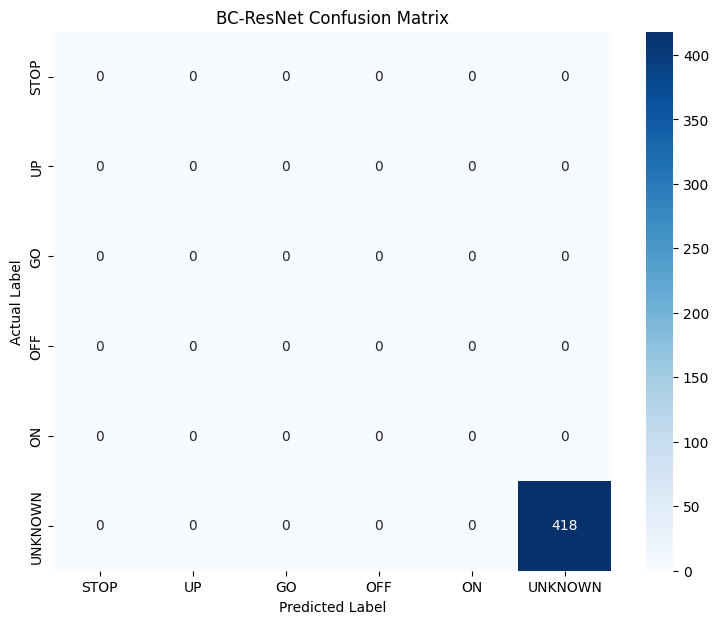

In [ ]:
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("BC-ResNet Confusion Matrix")

plt.show()

In [ ]:
import os

model_path = "/content/bcresnet_best.pth"

model_size = os.path.getsize(model_path) / (1024 * 1024)

dummy_input = torch.randn(1, 1, 40, 101).to(device)

model.eval()

with torch.no_grad():

    for _ in range(10):
        model(dummy_input)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for _ in range(100):
        model(dummy_input)

    if device.type == "cuda":
        torch.cuda.synchronize()

    end = time.perf_counter()

avg_time = (end - start) / 100

print("Model size:", round(model_size, 3), "MB")
print("Average inference time:", round(avg_time * 1000, 3), "ms")

Model size: 1.364 MB
Average inference time: 4.891 ms
